In [1]:
print("Hello, Data Science!")
print("My Week 1 assignment is ready.")

Hello, Data Science!
My Week 1 assignment is ready.


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("All libraries imported successfully!")
print("Pandas version:", pd.__version__)

All libraries imported successfully!
Pandas version: 3.0.6


In [3]:


import os
from pathlib import Path

PROJECT_ROOT = (
    Path.cwd().parent
    if Path.cwd().name == "notebooks"
    else Path.cwd()
)
os.chdir(PROJECT_ROOT)

import pandas as pd
from pathlib import Path

# Locate the dataset
file_path = Path("data/raw/ecommerce_sales_data.csv")

# Check whether the file exists
print("Dataset file found:", file_path.exists())

if file_path.exists():
    df = pd.read_csv(file_path)

    print("Dataset loaded successfully!")
    print("Number of rows:", df.shape[0])
    print("Number of columns:", df.shape[1])

    display(df.head())
else:
    print("File not found. Please check the data/raw folder.")


Dataset file found: True
Dataset loaded successfully!
Number of rows: 100
Number of columns: 12


,Order ID,Customer ID,Gender,Age,Product Category,Product Name,Quantity,Price,Order Date,Payment Method,City,Rating
0,ORD0001,CUST9376,Female,43,Home,Lamp,1,1368.69,07-06-2025,Cash on Delivery,Hyderabad,3
1,ORD0002,CUST3289,Male,57,Toys,Lego Set,5,782.44,11-12-2024,Cash on Delivery,Chennai,5
2,ORD0003,CUST6409,Female,53,Clothing,Jacket,1,3676.18,05-05-2025,Credit Card,Bangalore,4
3,ORD0004,CUST8815,Female,51,Beauty,Perfume,2,4836.37,25-06-2025,Cash on Delivery,Mumbai,5
4,ORD0005,CUST1018,Female,39,Electronics,Smartphone,4,3580.24,25-12-2024,UPI,Kolkata,3


In [4]:

# 1. Dataset overview

print("DATASET SHAPE")
print(df.shape)

print("\nCOLUMN NAMES")
print(df.columns.tolist())

print("\nDATA TYPES")
print(df.dtypes)

print("\nDATASET INFORMATION")
df.info()

print("\nSTATISTICAL SUMMARY")
display(df.describe(include="all"))


DATASET SHAPE
(100, 12)

COLUMN NAMES
['Order ID', 'Customer ID', 'Gender', 'Age', 'Product Category', 'Product Name', 'Quantity', 'Price', 'Order Date', 'Payment Method', 'City', 'Rating']

DATA TYPES
Order ID                str
Customer ID             str
Gender                  str
Age                   int64
Product Category        str
Product Name            str
Quantity              int64
Price               float64
Order Date              str
Payment Method          str
City                    str
Rating                int64
dtype: object

DATASET INFORMATION
<class 'pandas.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 12 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Order ID          100 non-null    str    
 1   Customer ID       100 non-null    str    
 2   Gender            100 non-null    str    
 3   Age               100 non-null    int64  
 4   Product Category  100 non-null    str    
 5   

,Order ID,Customer ID,Gender,Age,Product Category,Product Name,Quantity,Price,Order Date,Payment Method,City,Rating
count,100,100,100,100.000000,100,100,100.00000,100.000000,100,100,100,100.000000
unique,100,98,2,NaN,6,20,NaN,NaN,88,4,6,NaN
top,ORD0001,CUST6409,Female,NaN,Clothing,Lamp,NaN,NaN,06-07-2025,Netbanking,Chennai,NaN
freq,1,2,51,NaN,21,7,NaN,NaN,3,29,22,NaN
mean,NaN,NaN,NaN,37.720000,NaN,NaN,2.94000,2428.300600,NaN,NaN,NaN,3.000000
std,NaN,NaN,NaN,12.426007,NaN,NaN,1.44124,1508.115395,NaN,NaN,NaN,1.392621
min,NaN,NaN,NaN,18.000000,NaN,NaN,1.00000,118.330000,NaN,NaN,NaN,1.000000
25%,NaN,NaN,NaN,28.000000,NaN,NaN,2.00000,1130.615000,NaN,NaN,NaN,2.000000
50%,NaN,NaN,NaN,37.500000,NaN,NaN,3.00000,2160.355000,NaN,NaN,NaN,3.000000
75%,NaN,NaN,NaN,49.000000,NaN,NaN,4.00000,3743.872500,NaN,NaN,NaN,4.000000


In [5]:

# 2. Missing value analysis

missing_report = pd.DataFrame({
    "Missing Values": df.isnull().sum(),
    "Missing Percentage": (df.isnull().sum() / len(df) * 100).round(2)
})

display(missing_report)

print("Total missing cells:", df.isnull().sum().sum())


,Missing Values,Missing Percentage
Order ID,0,0.0
Customer ID,0,0.0
Gender,0,0.0
Age,0,0.0
Product Category,0,0.0
Product Name,0,0.0
Quantity,0,0.0
Price,0,0.0
Order Date,0,0.0
Payment Method,0,0.0


Total missing cells: 0


In [6]:

# 3. Duplicate analysis

print("Fully duplicated rows:", df.duplicated().sum())

print("Duplicate Order IDs:", df["Order ID"].duplicated().sum())

# Display any fully duplicated rows, if present
display(df[df.duplicated(keep=False)])


Fully duplicated rows: 0
Duplicate Order IDs: 0


,Order ID,Customer ID,Gender,Age,Product Category,Product Name,Quantity,Price,Order Date,Payment Method,City,Rating


In [7]:
print("Dataset shape:", df.shape)
print("\nMissing values:")
print(df.isnull().sum())
print("\nFully duplicated rows:", df.duplicated().sum())
print("Duplicate Order IDs:", df["Order ID"].duplicated().sum())
print("\nData types:")
print(df.dtypes)

Dataset shape: (100, 12)

Missing values:
Order ID            0
Customer ID         0
Gender              0
Age                 0
Product Category    0
Product Name        0
Quantity            0
Price               0
Order Date          0
Payment Method      0
City                0
Rating              0
dtype: int64

Fully duplicated rows: 0
Duplicate Order IDs: 0

Data types:
Order ID                str
Customer ID             str
Gender                  str
Age                   int64
Product Category        str
Product Name            str
Quantity              int64
Price               float64
Order Date              str
Payment Method          str
City                    str
Rating                int64
dtype: object


In [8]:

# TASK 1: Data validation checks

print("1. QUANTITY VALIDATION")
print("Zero or negative quantities:", (df["Quantity"] <= 0).sum())

print("\n2. PRICE VALIDATION")
print("Zero or negative prices:", (df["Price"] <= 0).sum())

print("\n3. AGE VALIDATION")
print("Negative ages:", (df["Age"] < 0).sum())

print("\n4. RATING VALIDATION")
print("Ratings outside 1-5:", (~df["Rating"].between(1, 5)).sum())

print("\n5. ORDER DATE VALIDATION")
parsed_dates = pd.to_datetime(
    df["Order Date"],
    format="mixed",
    dayfirst=True,
    errors="coerce"
)
print("Dates that could not be parsed:", parsed_dates.isna().sum())

print("\n6. CATEGORY VALUES")
for column in ["Gender", "Product Category", "Payment Method", "City"]:
    print(f"\n{column}:")
    print(df[column].value_counts(dropna=False))

print("\n7. TEXT WHITESPACE CHECK")
text_columns = df.select_dtypes(include=["object", "str"]).columns
for column in text_columns:
    whitespace_count = (
        df[column].astype("string").str.strip().ne(df[column].astype("string"))
    ).sum()
    if whitespace_count:
        print(f"{column}: {whitespace_count} values contain extra whitespace")

print("\nValidation checks complete.")


1. QUANTITY VALIDATION
Zero or negative quantities: 0

2. PRICE VALIDATION
Zero or negative prices: 0

3. AGE VALIDATION
Negative ages: 0

4. RATING VALIDATION
Ratings outside 1-5: 0

5. ORDER DATE VALIDATION
Dates that could not be parsed: 0

6. CATEGORY VALUES

Gender:
Gender
Female    51
Male      49
Name: count, dtype: int64

Product Category:
Product Category
Clothing       21
Electronics    19
Books          18
Home           17
Beauty         13
Toys           12
Name: count, dtype: int64

Payment Method:
Payment Method
Netbanking          29
Cash on Delivery    24
UPI                 24
Credit Card         23
Name: count, dtype: int64

City:
City
Chennai      22
Mumbai       20
Kolkata      20
Hyderabad    15
Bangalore    14
Delhi         9
Name: count, dtype: int64

7. TEXT WHITESPACE CHECK

Validation checks complete.


In [9]:

# TASK 1: Create cleaned dataset

from pathlib import Path

# Preserve original data
cleaned_df = df.copy()

# Standardize text fields
text_columns = [
    "Gender", "Product Category",
    "Product Name", "Payment Method", "City"
]

for col in text_columns:
    cleaned_df[col] = cleaned_df[col].str.strip()

# Convert dates to a consistent format
cleaned_df["Order Date"] = pd.to_datetime(
    cleaned_df["Order Date"],
    format="mixed",
    dayfirst=True,
    errors="raise"
)

# Calculate transaction revenue
cleaned_df["Total Amount"] = (
    cleaned_df["Quantity"] * cleaned_df["Price"]
).round(2)

# Save cleaned dataset
output_path = Path("data/cleaned/cleaned_dataset.csv")
output_path.parent.mkdir(parents=True, exist_ok=True)

cleaned_df.to_csv(output_path, index=False)

print("Cleaned dataset saved successfully!")
print("Rows:", cleaned_df.shape[0])
print("Columns:", cleaned_df.shape[1])

display(cleaned_df.head())


Cleaned dataset saved successfully!
Rows: 100
Columns: 13


,Order ID,Customer ID,Gender,Age,Product Category,Product Name,Quantity,Price,Order Date,Payment Method,City,Rating,Total Amount
0,ORD0001,CUST9376,Female,43,Home,Lamp,1,1368.69,2025-06-07,Cash on Delivery,Hyderabad,3,1368.69
1,ORD0002,CUST3289,Male,57,Toys,Lego Set,5,782.44,2024-12-11,Cash on Delivery,Chennai,5,3912.20
2,ORD0003,CUST6409,Female,53,Clothing,Jacket,1,3676.18,2025-05-05,Credit Card,Bangalore,4,3676.18
3,ORD0004,CUST8815,Female,51,Beauty,Perfume,2,4836.37,2025-06-25,Cash on Delivery,Mumbai,5,9672.74
4,ORD0005,CUST1018,Female,39,Electronics,Smartphone,4,3580.24,2024-12-25,UPI,Kolkata,3,14320.96


### Task 1: Data Cleaning Summary

The e-commerce dataset initially contained 100 records and 12 columns.

The initial inspection identified no missing values, fully duplicated records, or repeated Order IDs.

Validation checks found no zero or negative quantities, zero or negative prices, negative ages, ratings outside the expected range, or unparseable order dates.

Text fields were standardized by stripping surrounding whitespace, order dates were converted into a consistent date format, and a new Total Amount column was calculated using Quantity × Price.

No rows were removed. The original dataset was preserved, and the processed dataset was saved separately for further analysis.

Further review of categorical consistency may still be necessary.

In [10]:

# TASK 2: Sales Data Analysis

# Total revenue
total_revenue = cleaned_df["Total Amount"].sum()

# Total orders
total_orders = cleaned_df["Order ID"].nunique()

# Average order value
average_order_value = total_revenue / total_orders if total_orders else 0

# Total units sold
total_units_sold = cleaned_df["Quantity"].sum()

# Revenue by category
category_revenue = (
    cleaned_df.groupby("Product Category")["Total Amount"]
    .sum()
    .sort_values(ascending=False)
)

# Revenue by product
product_revenue = (
    cleaned_df.groupby("Product Name")["Total Amount"]
    .sum()
    .sort_values(ascending=False)
)

print("SALES KPI SUMMARY")
print("-" * 40)
print(f"Total Revenue: ₹{total_revenue:,.2f}")
print(f"Total Orders: {total_orders}")
print(f"Average Order Value: ₹{average_order_value:,.2f}")
print(f"Total Units Sold: {total_units_sold}")

print("\nRevenue by Category:")
display(category_revenue.to_frame("Total Revenue"))

print("\nTop Revenue-Generating Product:")
display(product_revenue.head(1).to_frame("Total Revenue"))

print("\nTop-Selling Category by Revenue:")
print(category_revenue.index[0])


SALES KPI SUMMARY
----------------------------------------
Total Revenue: ₹694,219.87
Total Orders: 100
Average Order Value: ₹6,942.20
Total Units Sold: 294

Revenue by Category:


,Total Revenue
Product Category,
Electronics,140811.26
Home,136365.47
Books,129177.30
Clothing,121504.99
Beauty,84457.92
Toys,81902.93



Top Revenue-Generating Product:


,Total Revenue
Product Name,
Curtains,79023.1



Top-Selling Category by Revenue:
Electronics


In [11]:

# TASK 2: Trend and customer analysis

# Ensure dates are datetime values
cleaned_df["Order Date"] = pd.to_datetime(cleaned_df["Order Date"])

# Create a monthly sales summary
cleaned_df["Month"] = cleaned_df["Order Date"].dt.to_period("M")

monthly_sales = (
    cleaned_df.groupby("Month")["Total Amount"]
    .sum()
    .sort_index()
)

print("MONTHLY REVENUE")
display(monthly_sales.to_frame("Revenue"))

print("\nTOP 5 PRODUCTS BY UNITS SOLD")
top_products = (
    cleaned_df.groupby("Product Name")["Quantity"]
    .sum()
    .sort_values(ascending=False)
    .head(5)
)
display(top_products.to_frame("Units Sold"))

print("\nORDERS BY CITY")
city_orders = cleaned_df.groupby("City")["Order ID"].nunique().sort_values(ascending=False)
display(city_orders.to_frame("Number of Orders"))

print("\nCUSTOMER INSIGHTS")
customer_orders = cleaned_df.groupby("Customer ID").agg(
    Orders=("Order ID", "nunique"),
    Revenue=("Total Amount", "sum")
)

print("Unique customers:", cleaned_df["Customer ID"].nunique())
print("Repeat customers:", (customer_orders["Orders"] > 1).sum())
print("Revenue from repeat customers: ₹{:,.2f}".format(
    customer_orders.loc[customer_orders["Orders"] > 1, "Revenue"].sum()
))


MONTHLY REVENUE


,Revenue
Month,
2024-07,17411.29
2024-08,94121.76
2024-09,90122.59
2024-10,26986.55
2024-11,58692.98
2024-12,44666.03
2025-01,51865.59
2025-02,39294.12
2025-03,37495.60



TOP 5 PRODUCTS BY UNITS SOLD


,Units Sold
Product Name,
Curtains,25
Smartphone,25
Comics,23
Fiction,20
Smartwatch,19



ORDERS BY CITY


,Number of Orders
City,
Chennai,22
Kolkata,20
Mumbai,20
Hyderabad,15
Bangalore,14
Delhi,9



CUSTOMER INSIGHTS
Unique customers: 98
Repeat customers: 2
Revenue from repeat customers: ₹17,107.31


In [12]:
print("Highest-revenue month:", monthly_sales.idxmax())
print("Highest monthly revenue: ₹{:,.2f}".format(monthly_sales.max()))

print("\nTop product by units sold:")
print(top_products.head(1))

print("\nCity with most orders:")
print(city_orders.head(1))

print("\nUnique customers:", cleaned_df["Customer ID"].nunique())
print("Repeat customers:", (customer_orders["Orders"] > 1).sum())

Highest-revenue month: 2024-08
Highest monthly revenue: ₹94,121.76

Top product by units sold:
Product Name
Curtains    25
Name: Quantity, dtype: int64

City with most orders:
City
Chennai    22
Name: Order ID, dtype: int64

Unique customers: 98
Repeat customers: 2


### Task 2: Business Observations

1. **Overall sales performance:** The dataset recorded total revenue of ₹694,219.87 across 100 orders, with an average order value of ₹6,942.20.

2. **Leading product category:** Electronics generated the highest category revenue at ₹140,811.26, making it the strongest category by revenue in this dataset.

3. **Top product by demand:** Curtains sold 25 units, making them the top product by quantity sold.

4. **Highest-revenue month:** August 2024 recorded the highest monthly revenue, at ₹94,121.76.

5. **City-wise orders:** Chennai recorded the highest number of orders, with 22 orders, indicating that it was the leading city by order volume in this dataset.

6. **Customer retention opportunity:** The dataset contains 98 unique customers and only 2 repeat customers. This suggests an opportunity to investigate customer retention and encourage repeat purchases.

7. **Revenue concentration:** Curtains generated ₹79,023.10 in revenue, making them the highest-revenue product in the product-level analysis.

8. **Repeat-customer contribution:** Repeat customers generated ₹17,107.31 in revenue. The business could examine what encourages these customers to return and test targeted retention strategies.

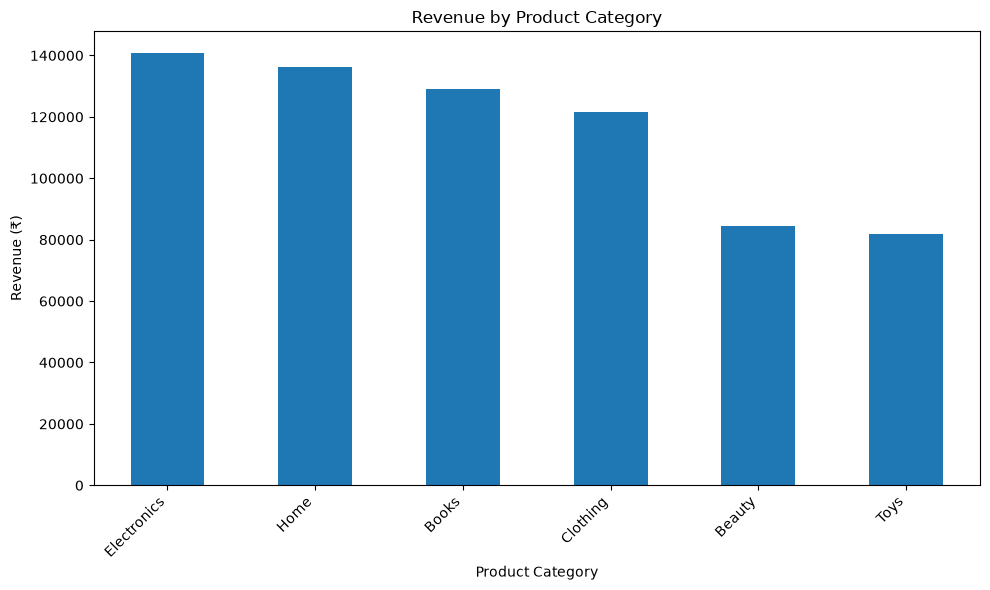

In [13]:

# TASK 3: Bar chart — Revenue by product category

import matplotlib.pyplot as plt
from pathlib import Path

chart_dir = Path("outputs/charts")
chart_dir.mkdir(parents=True, exist_ok=True)

category_revenue = (
    cleaned_df.groupby("Product Category")["Total Amount"]
    .sum()
    .sort_values(ascending=False)
)

plt.figure(figsize=(10, 6))
category_revenue.plot(kind="bar")

plt.title("Revenue by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Revenue (₹)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()

plt.savefig(chart_dir / "revenue_by_category.png", dpi=300)
plt.show()


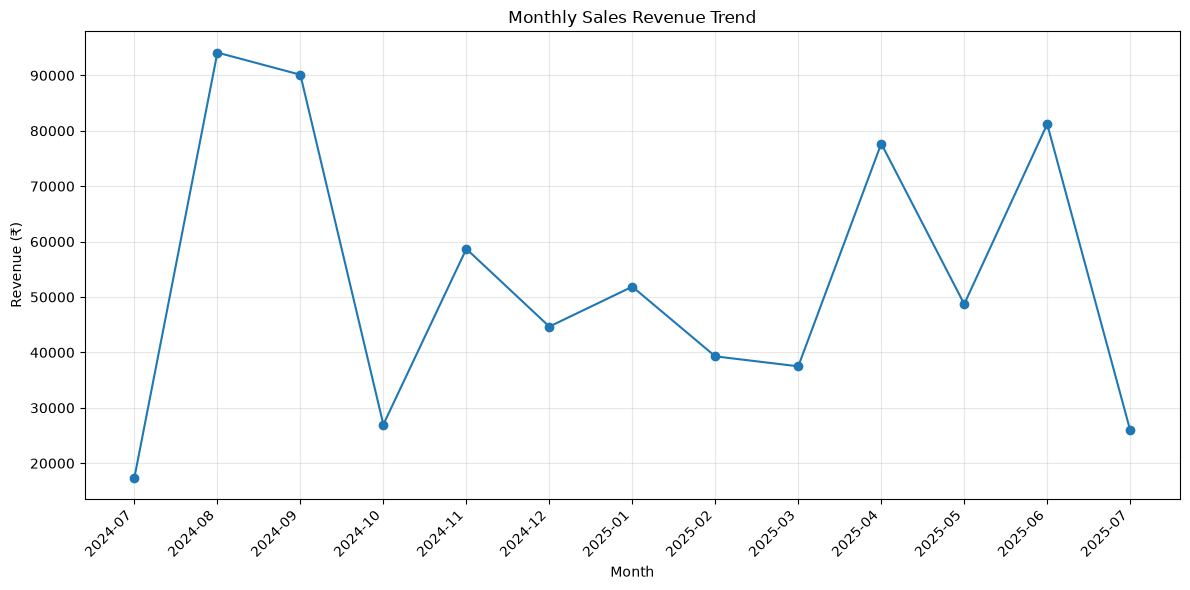

Highest-revenue month: 2024-08
Highest monthly revenue: ₹94,121.76


In [14]:

# Line chart: Monthly revenue trend

monthly_revenue = (
    cleaned_df.assign(
        Month=cleaned_df["Order Date"].dt.to_period("M")
    )
    .groupby("Month")["Total Amount"]
    .sum()
)

plt.figure(figsize=(12, 6))
plt.plot(
    monthly_revenue.index.astype(str),
    monthly_revenue.values,
    marker="o"
)

plt.title("Monthly Sales Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Revenue (₹)")
plt.xticks(rotation=45, ha="right")
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig(chart_dir / "monthly_sales_trend.png", dpi=300)
plt.show()

print("Highest-revenue month:", monthly_revenue.idxmax())
print(f"Highest monthly revenue: ₹{monthly_revenue.max():,.2f}")


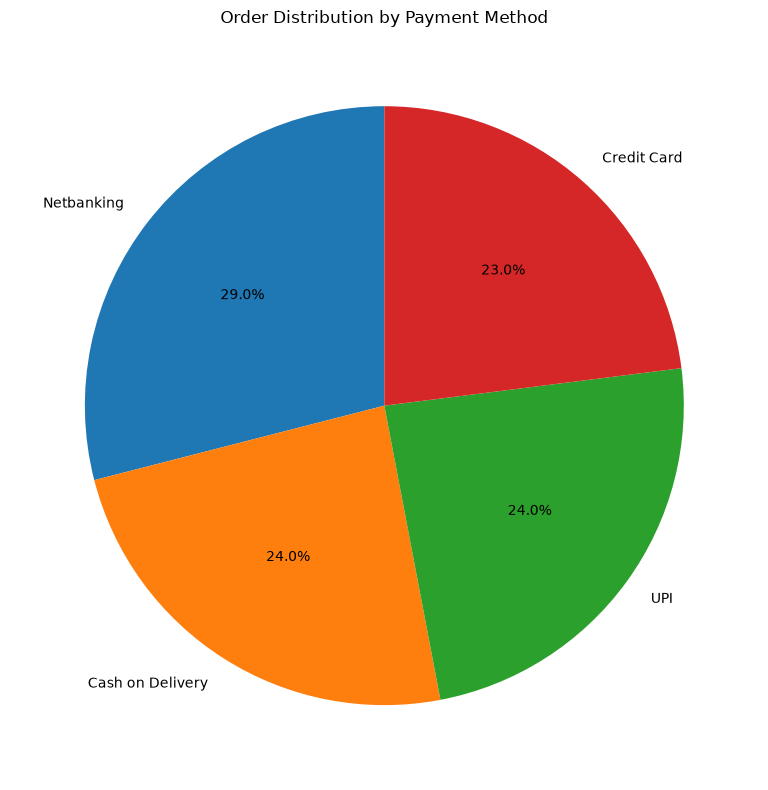

In [15]:

# Pie chart: Order distribution by payment method

payment_counts = cleaned_df["Payment Method"].value_counts()

plt.figure(figsize=(8, 8))
plt.pie(
    payment_counts,
    labels=payment_counts.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Order Distribution by Payment Method")
plt.tight_layout()

plt.savefig(chart_dir / "payment_method_distribution.png", dpi=300)
plt.show()


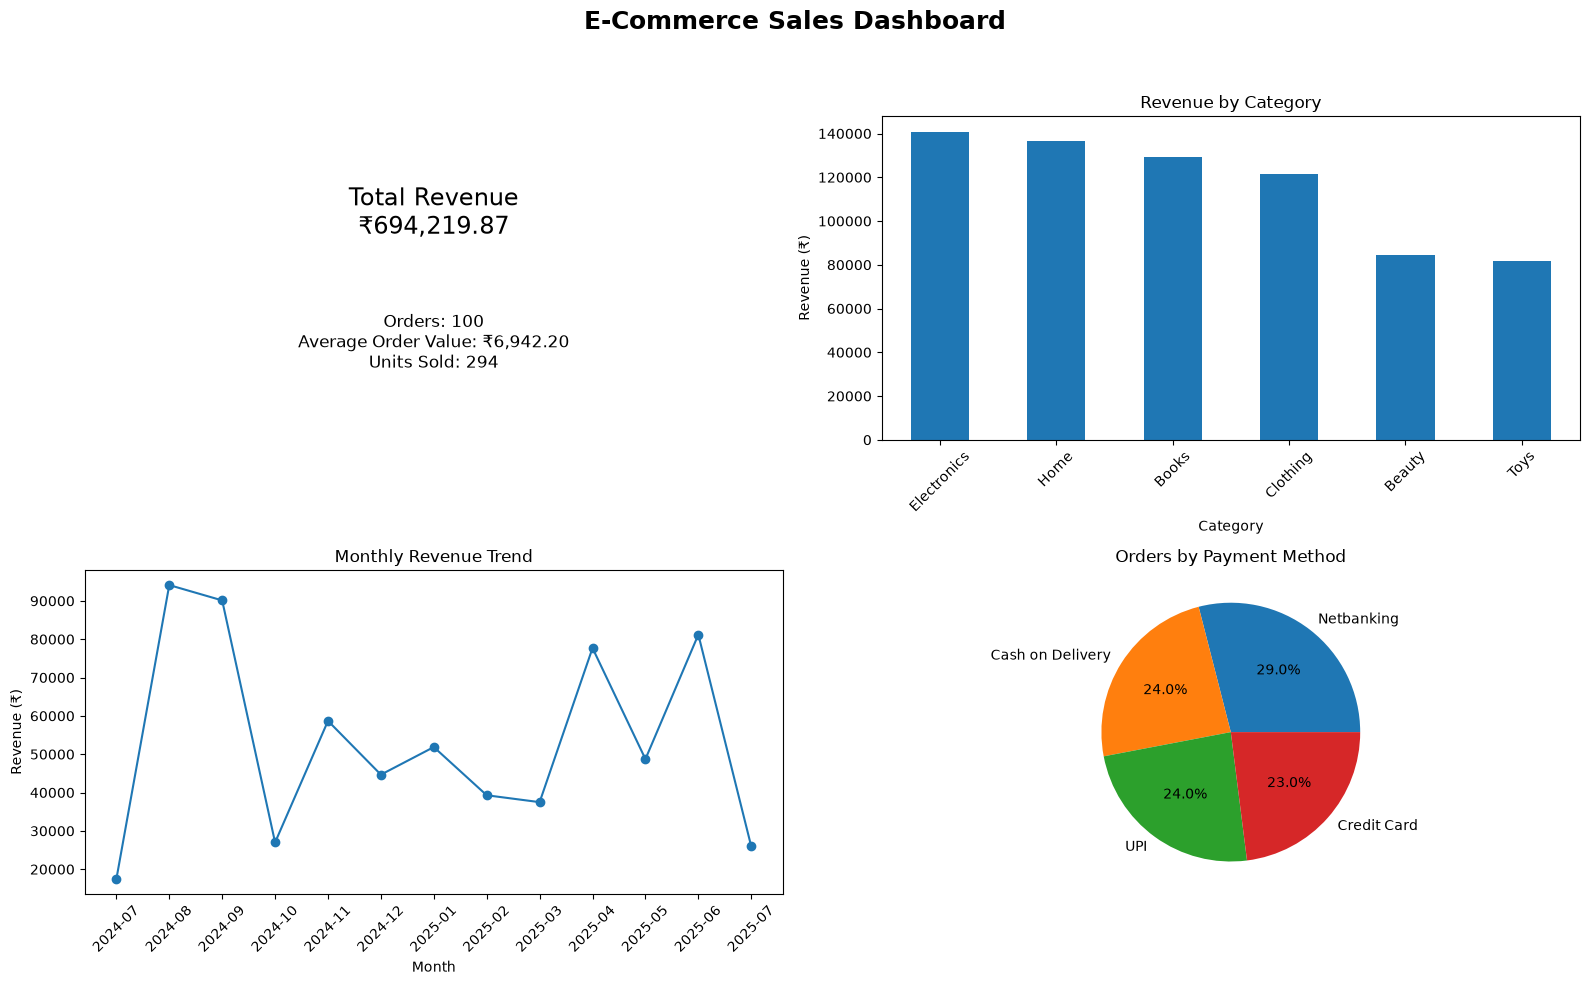

Dashboard saved successfully!


In [16]:

# Dashboard mockup: Sales overview

fig, axes = plt.subplots(2, 2, figsize=(16, 10))
fig.suptitle("E-Commerce Sales Dashboard", fontsize=18, fontweight="bold")

# KPI cards
axes[0, 0].axis("off")
axes[0, 0].text(
    0.5, 0.7,
    f"Total Revenue\n₹{total_revenue:,.2f}",
    ha="center", va="center", fontsize=17
)
axes[0, 0].text(
    0.5, 0.3,
    f"Orders: {total_orders}\nAverage Order Value: ₹{average_order_value:,.2f}\nUnits Sold: {total_units_sold}",
    ha="center", va="center", fontsize=12
)

# Category revenue
category_revenue.plot(kind="bar", ax=axes[0, 1])
axes[0, 1].set_title("Revenue by Category")
axes[0, 1].set_xlabel("Category")
axes[0, 1].set_ylabel("Revenue (₹)")
axes[0, 1].tick_params(axis="x", rotation=45)

# Monthly revenue trend
axes[1, 0].plot(
    monthly_revenue.index.astype(str),
    monthly_revenue.values,
    marker="o"
)
axes[1, 0].set_title("Monthly Revenue Trend")
axes[1, 0].set_xlabel("Month")
axes[1, 0].set_ylabel("Revenue (₹)")
axes[1, 0].tick_params(axis="x", rotation=45)

# Payment method distribution
axes[1, 1].pie(
    payment_counts,
    labels=payment_counts.index,
    autopct="%1.1f%%"
)
axes[1, 1].set_title("Orders by Payment Method")

plt.tight_layout(rect=[0, 0, 1, 0.95])

dashboard_dir = Path("outputs/dashboard")
dashboard_dir.mkdir(parents=True, exist_ok=True)

plt.savefig(
    dashboard_dir / "dashboard_mockup.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

print("Dashboard saved successfully!")


In [17]:

from pathlib import Path

required_files = [
    Path("data/cleaned/cleaned_dataset.csv"),
    Path("outputs/charts/revenue_by_category.png"),
    Path("outputs/charts/monthly_sales_trend.png"),
    Path("outputs/charts/payment_method_distribution.png"),
    Path("outputs/dashboard/dashboard_mockup.png"),
]

print("PROJECT OUTPUT CHECK")
for file in required_files:
    status = "FOUND" if file.exists() else "MISSING"
    print(f"{status}: {file}")


PROJECT OUTPUT CHECK
FOUND: data/cleaned/cleaned_dataset.csv
FOUND: outputs/charts/revenue_by_category.png
FOUND: outputs/charts/monthly_sales_trend.png
FOUND: outputs/charts/payment_method_distribution.png
FOUND: outputs/dashboard/dashboard_mockup.png


### Chart 1: Revenue by Product Category

Electronics generated the highest category revenue at ₹140,811.26, followed by Home at ₹136,365.47. This indicates that Electronics and Home were the leading categories by revenue in the analyzed dataset.

### Chart 2: Monthly Sales Trend

August 2024 recorded the highest monthly revenue of ₹94,121.76. Further investigation of monthly fluctuations could help identify periods of stronger sales performance.

### Chart 3: Payment Method Distribution

The pie chart shows the distribution of orders across different payment methods. The most frequently used payment method accounted for the largest share of orders. This analysis helps identify customer payment preferences and can support decisions about payment options.

In [18]:

from pathlib import Path
import os

print("Current working directory:")
print(os.getcwd())

checks = [
    "data/raw/ecommerce_sales_data.csv",
    "data/cleaned/cleaned_dataset.csv",
    "outputs/charts/revenue_by_category.png",
    "outputs/charts/monthly_sales_trend.png",
    "outputs/charts/payment_method_distribution.png",
    "outputs/dashboard/dashboard_mockup.png",
]

print("\nFILE CHECK")
for file in checks:
    print(f"{'FOUND' if Path(file).exists() else 'MISSING'}: {file}")


Current working directory:
/Users/sankalppadhi/Documents/data-science-week1-assignment

FILE CHECK
FOUND: data/raw/ecommerce_sales_data.csv
FOUND: data/cleaned/cleaned_dataset.csv
FOUND: outputs/charts/revenue_by_category.png
FOUND: outputs/charts/monthly_sales_trend.png
FOUND: outputs/charts/payment_method_distribution.png
FOUND: outputs/dashboard/dashboard_mockup.png


In [19]:

from pathlib import Path
import os

# Set the project root to the parent folder
PROJECT_ROOT = Path.cwd().parent
os.chdir(PROJECT_ROOT)

print("Project root:", Path.cwd())

checks = [
    "data/raw/ecommerce_sales_data.csv",
    "data/cleaned/cleaned_dataset.csv",
    "outputs/charts/revenue_by_category.png",
    "outputs/charts/monthly_sales_trend.png",
    "outputs/charts/payment_method_distribution.png",
    "outputs/dashboard/dashboard_mockup.png",
]

print("\nFILE CHECK")
for file in checks:
    print(f"{'FOUND' if Path(file).exists() else 'MISSING'}: {file}")


Project root: /Users/sankalppadhi/Documents

FILE CHECK
MISSING: data/raw/ecommerce_sales_data.csv
MISSING: data/cleaned/cleaned_dataset.csv
MISSING: outputs/charts/revenue_by_category.png
MISSING: outputs/charts/monthly_sales_trend.png
MISSING: outputs/charts/payment_method_distribution.png
MISSING: outputs/dashboard/dashboard_mockup.png
